# 11 · Inference demo: from a radar chip to a water map (task T31)

`src/predict.py` is the model as someone would use it, outside the training code:

```
python src/predict.py --chip data/s1/Bolivia_103757_S1Hand.tif
```

It loads the best-validation model, reads one chip, preprocesses it with the same function and the same normalisation file as training, predicts, thresholds at 0.5 and saves a picture (and, on request, a georeferenced GeoTIFF of the mask).

This notebook runs it on chips that were **not used in training** and checks one thing in particular: that the demo gives exactly the score recorded when the model was evaluated. The classic demo bug is preprocessing that differs slightly from training; if that happened here, the numbers would not match.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401

import pandas as pd
import rasterio
from IPython.display import Image, display

from src.config import run_dir

best = json.loads((ROOT / "results" / "best_run.json").read_text())
RUN = best["run_id"]
recorded = pd.read_csv(run_dir(RUN) / "per_chip.csv").set_index("chip")
print(f"model used by the demo: {RUN} ({best['config']}, seed {best['seed']}), chosen by validation IoU {best['val_iou']:.4f}")


def demo(chip, tif=None):
    """Run the command-line demo exactly as a user would and show what it printed and saved."""
    cmd = [sys.executable, "src/predict.py", "--chip", f"data/s1/{chip}_S1Hand.tif"]
    if tif:
        cmd += ["--tif", tif]
    print("$ python " + " ".join(cmd[1:]))
    done = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    assert done.returncode == 0, done.stderr[-2000:]
    print(done.stdout)
    display(Image(filename=str(ROOT / "figures" / "demo" / f"{chip}_{RUN}.png"), width=900))
    return done.stdout

model used by the demo: R19 (MobileNetV2 + ImageNet, seed 0), chosen by validation IoU 0.6697


## 1. A chip from the flood the model has never seen (Bolivia)

The Bolivia chip with the median IoU of the fifteen, so neither a showcase nor a failure. The mask is also written as a GeoTIFF.

$ python src/predict.py --chip data/s1/Bolivia_379434_S1Hand.tif --tif figures/demo/Bolivia_379434_R19_mask.tif


chip   : Bolivia_379434_S1Hand.tif  (512x512 pixels)
model  : R19, MobileNetV2 + ImageNet (mobilenetv2_imagenet, channels vv_vh_ratio, loss bce_dice)
water  : 4.2% of the pixels with radar data (3.76 s)
label  : 4.1% water | IoU 0.276  precision 0.427  recall 0.438
figure : /mnt/d/Projects/College Project/FloodWatch/floodwatch/figures/demo/Bolivia_379434_R19.png
geotiff: figures/demo/Bolivia_379434_R19_mask.tif



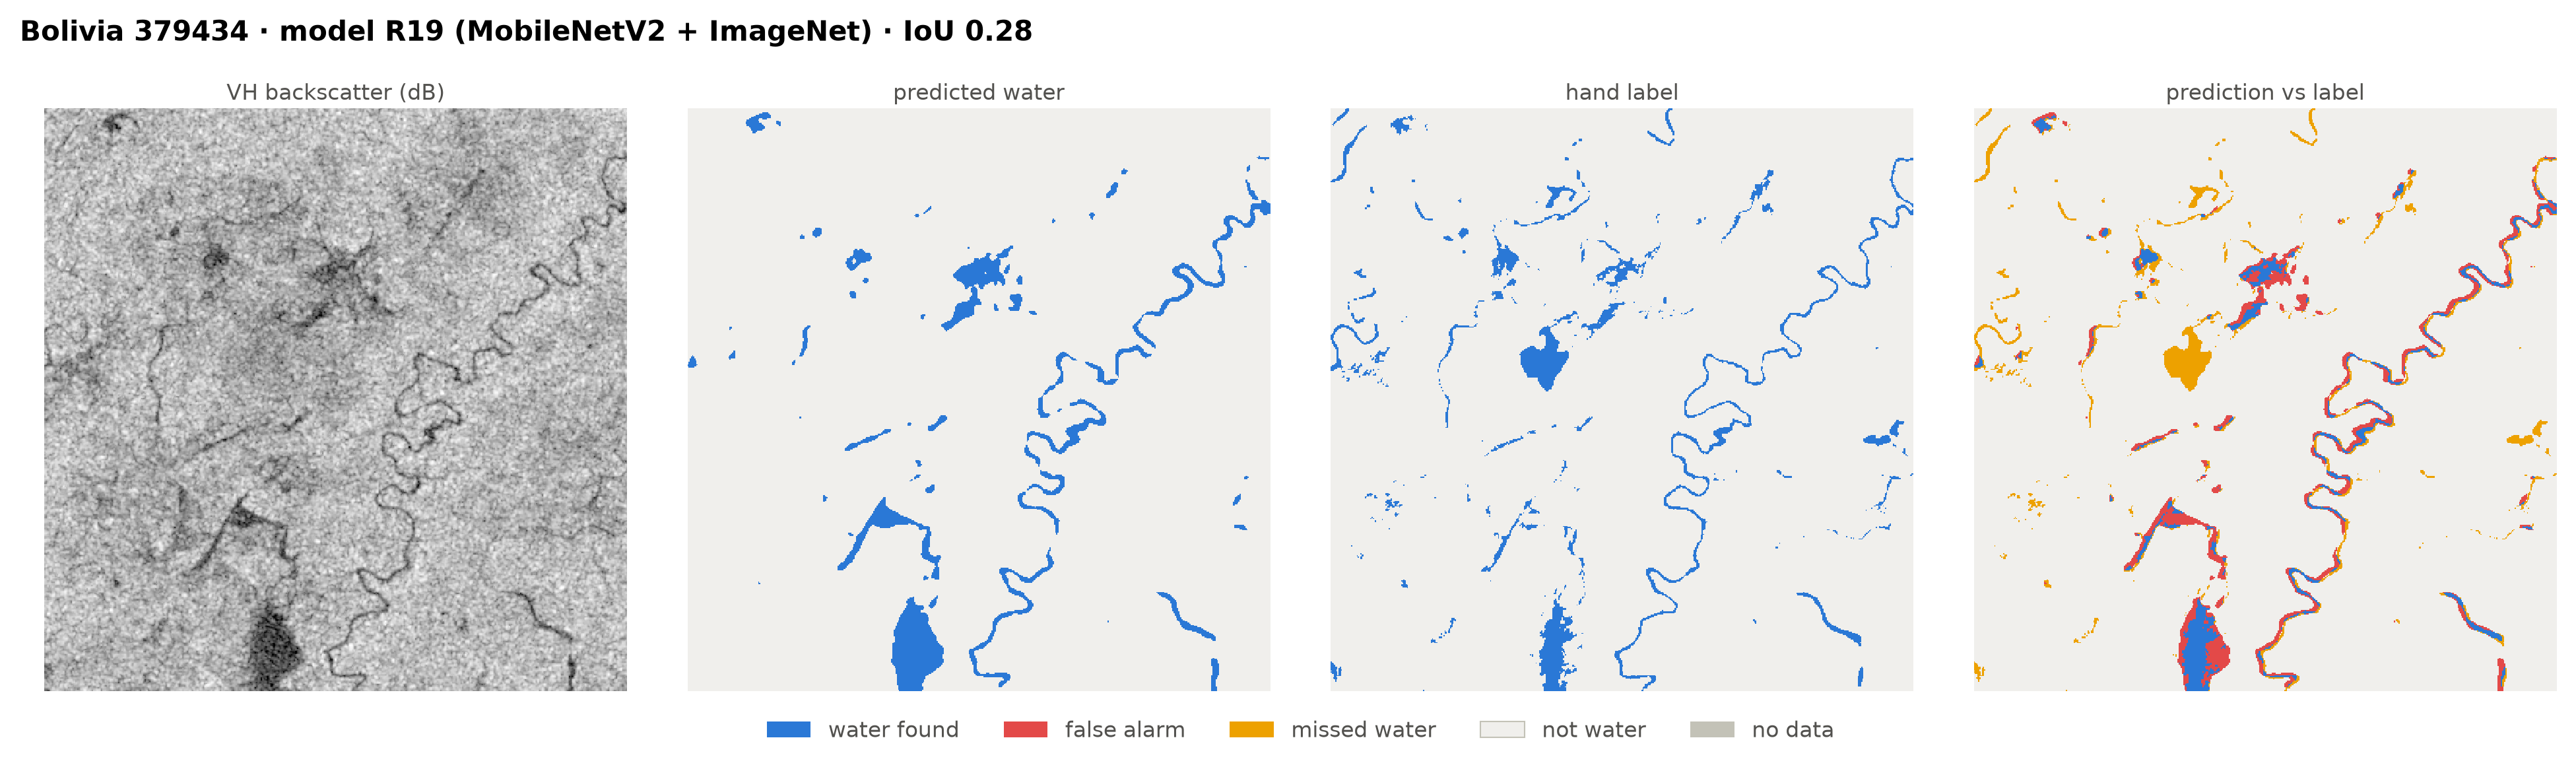

In [2]:
bolivia = recorded[(recorded["split"] == "bolivia")].sort_values("iou")
chip = bolivia.index[len(bolivia) // 2]
out = demo(chip, tif=f"figures/demo/{chip}_{RUN}_mask.tif")

In [3]:
with rasterio.open(ROOT / "figures" / "demo" / f"{chip}_{RUN}_mask.tif") as f:
    mask = f.read(1)
    print("GeoTIFF:", f.width, "x", f.height, "pixels |", f.crs, "| pixel size", tuple(round(abs(v), 7) for v in f.res),
          "degrees | nodata", f.nodata)
    print("bounds:", tuple(round(v, 4) for v in f.bounds))
with rasterio.open(ROOT / "data" / "s1" / f"{chip}_S1Hand.tif") as f:
    print("same grid as the input chip:", f.bounds == rasterio.open(ROOT / "figures" / "demo" / f"{chip}_{RUN}_mask.tif").bounds)
print("values in the mask:", {int(v): int((mask == v).sum()) for v in sorted(set(mask.ravel().tolist()))})

GeoTIFF: 512 x 512 pixels | EPSG:4326 | pixel size (8.98e-05, 8.98e-05) degrees | nodata 255.0
bounds: (-65.4491, -15.1779, -65.4031, -15.1319)
same grid as the input chip: True
values in the mask: {0: 251080, 1: 11064}


## 2. A test chip (a new place within a familiar flood)

The test chip at the 75th percentile of IoU among the test chips with at least 2% water.

$ python src/predict.py --chip data/s1/USA_67102_S1Hand.tif


chip   : USA_67102_S1Hand.tif  (512x512 pixels)
model  : R19, MobileNetV2 + ImageNet (mobilenetv2_imagenet, channels vv_vh_ratio, loss bce_dice)
water  : 3.7% of the pixels with radar data (3.77 s)
label  : 3.6% water | IoU 0.789  precision 0.876  recall 0.888
figure : /mnt/d/Projects/College Project/FloodWatch/floodwatch/figures/demo/USA_67102_R19.png



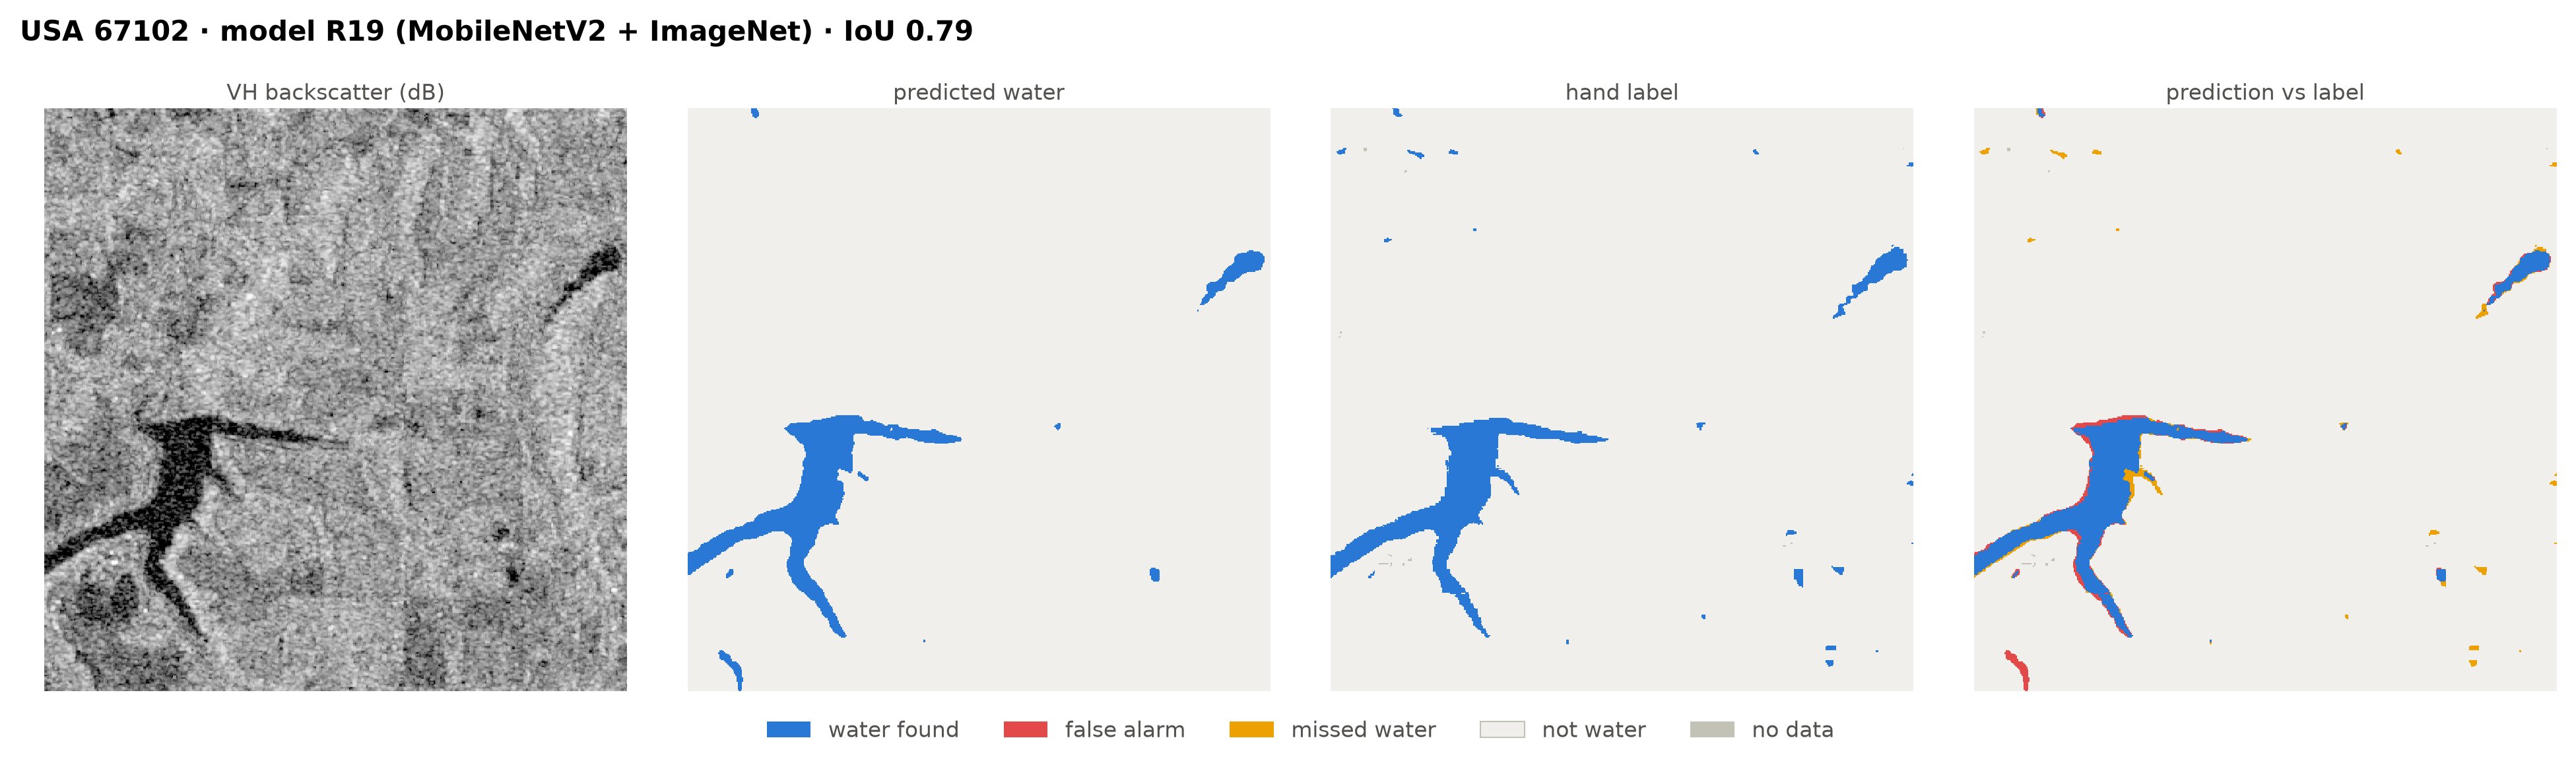

In [4]:
test = recorded[(recorded["split"] == "test") & (recorded["water_frac"] >= 0.02)].sort_values("iou")
chip2 = test.index[int(round(0.75 * (len(test) - 1)))]
out2 = demo(chip2)

## 3. Does the demo agree with the evaluation?

The IoU printed by the demo for each chip, next to the IoU stored in `results/<run>/per_chip.csv` when the run was scored on test and Bolivia.

In [5]:
def printed_iou(text):
    line = next(l for l in text.splitlines() if l.startswith("label"))
    return float(line.split("IoU")[1].split()[0])

check = pd.DataFrame({"IoU printed by the demo": {chip: printed_iou(out), chip2: printed_iou(out2)},
                      "IoU recorded at evaluation": {chip: recorded.loc[chip, "iou"], chip2: recorded.loc[chip2, "iou"]}})
check["difference"] = (check["IoU printed by the demo"] - check["IoU recorded at evaluation"]).abs()
assert (check["difference"] < 1e-3).all(), "the demo does not reproduce the evaluation: check the preprocessing"
check

,IoU printed by the demo,IoU recorded at evaluation,difference
Bolivia_379434,0.276,0.275922,0.000078
USA_67102,0.789,0.788809,0.000191
